In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

file_path = r"C:\Users\yadav\Downloads\archive (5).zip"

with zipfile.ZipFile(file_path, "r") as z:
    print(z.namelist())

['clean_final_data.csv', 'customers.csv', 'orders.csv', 'payments.csv', 'products.csv']


In [15]:

df.head('customers.csv')
df.head('orders.csv')
df.head('products.csv')
df.head('clean_final_data.csv')
df.head('payments.csv')








NameError: name 'df' is not defined

In [16]:
with zipfile.ZipFile(file_path, "r") as z:
    df = pd.read_csv(z.open("clean_final_data.csv"))

df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


In [19]:
df.columns

Index(['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity',
       'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate',
       'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales',
       'OrderValue'],
      dtype='str')

In [24]:
df.isnull().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

In [26]:
df.dtypes

OrderID              int64
CustomerID           int64
OrderDate              str
ProductID            int64
Quantity           float64
Discount           float64
PaymentMethod          str
Status                 str
Age                float64
City                   str
SignupDate             str
CustomerSegment        str
ProductName            str
Category               str
UnitPrice          float64
Sales              float64
OrderValue         float64
dtype: object

In [35]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["SignupDate"] = pd.to_datetime(df["SignupDate"])                               

In [37]:
df.dtypes

OrderID                     int64
CustomerID                  int64
OrderDate          datetime64[us]
ProductID                   int64
Quantity                  float64
Discount                  float64
PaymentMethod                 str
Status                        str
Age                       float64
City                          str
SignupDate         datetime64[us]
CustomerSegment               str
ProductName                   str
Category                      str
UnitPrice                 float64
Sales                     float64
OrderValue                float64
dtype: object

In [38]:
df.duplicated().sum()

np.int64(0)

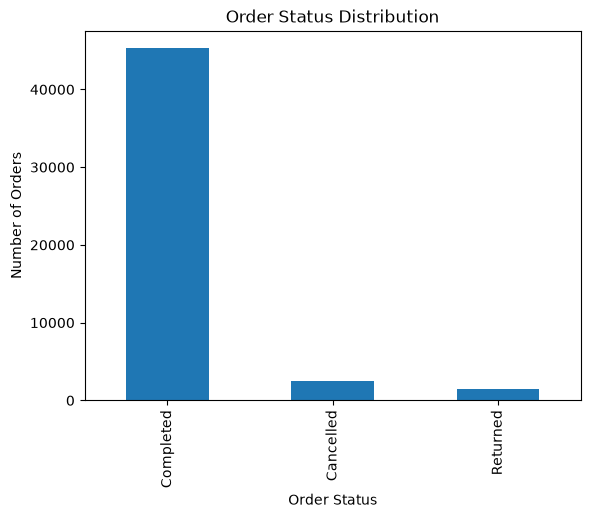

In [39]:
df["Status"].value_counts().plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.show()

In [40]:
df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Sales=("Sales", "mean"),
    Unique_Products=("ProductName", "nunique")
).sort_values("Total_Sales", ascending=False)

,Total_Sales,Total_Quantity,Average_Sales,Unique_Products
Category,,,,
Electronics,1751037.0,33030.0,98.566676,9
Accessories,553023.0,34524.0,30.404255,5
Home Office,446065.0,5920.0,142.877963,2
Wearables,429450.0,5675.0,141.127177,2
Gaming,198037.0,3152.0,119.084185,1
Stationery,67218.0,10331.0,12.356250,1


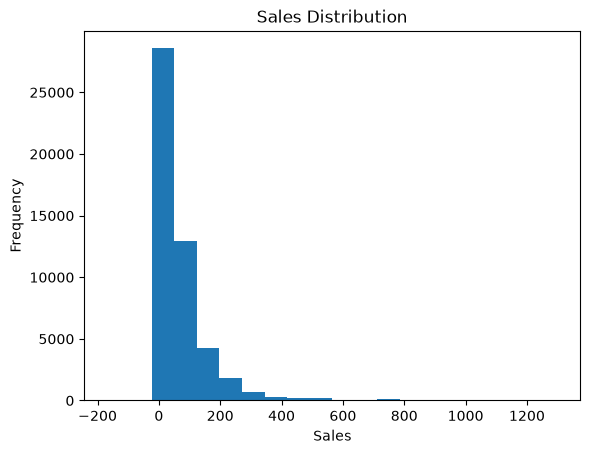

In [41]:
plt.hist(df["Sales"].dropna(), bins=20)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

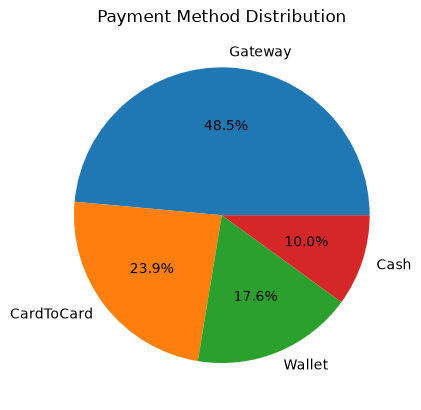

In [42]:
df["PaymentMethod"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()

In [43]:
df.groupby("CustomerSegment")["Sales"].sum().sort_values(ascending=False)

CustomerSegment
Regular    1914854.0
New        1196104.0
VIP         333872.0
Name: Sales, dtype: float64

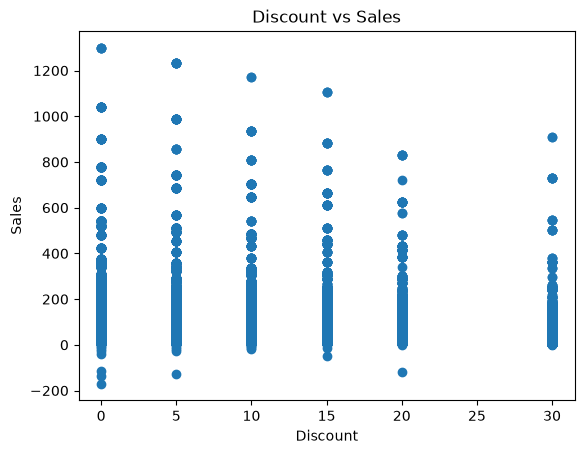

In [44]:
plt.scatter(df["Discount"], df["Sales"])

plt.title("Discount vs Sales")
plt.xlabel("Discount")
plt.ylabel("Sales")
plt.show()

In [48]:
df["YearMonth"] = df["OrderDate"].dt.to_period("M")

monthly_sales = df.groupby("YearMonth")["Sales"].sum()


monthly_sales

YearMonth
2024-01    121893.0
2024-02    114664.0
2024-03    128150.0
2024-04    115941.0
2024-05    123683.0
2024-06    116784.0
2024-07    128689.0
2024-08    129987.0
2024-09    115943.0
2024-10    117260.0
2024-11    121208.0
2024-12    125897.0
2025-01    118487.0
2025-02    108609.0
2025-03    119432.0
2025-04    115278.0
2025-05    130607.0
2025-06    126269.0
2025-07    119743.0
2025-08    120441.0
2025-09    119935.0
2025-10    124299.0
2025-11    125300.0
2025-12    115790.0
2026-01    130550.0
2026-02     75132.0
2026-03     84082.0
2026-04     85706.0
2026-05     85986.0
2026-06     79085.0
Freq: M, Name: Sales, dtype: float64

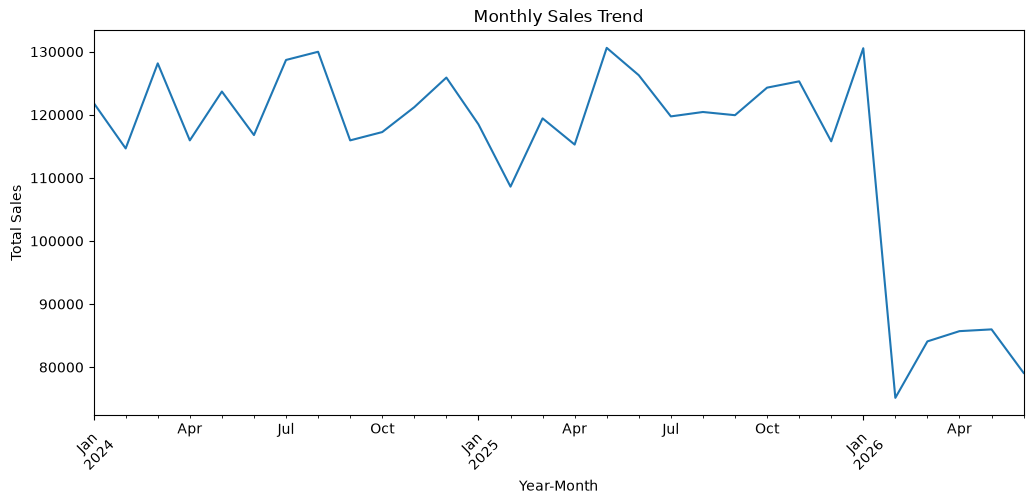

In [49]:
monthly_sales.plot(kind="line", figsize=(12, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [50]:
df["DayOfWeek"] = df["OrderDate"].dt.day_name()

df.groupby("DayOfWeek")["Sales"].sum()

DayOfWeek
Friday       508819.0
Monday       471094.0
Saturday     540913.0
Sunday       550708.0
Thursday     462113.0
Tuesday      450081.0
Wednesday    461102.0
Name: Sales, dtype: float64

In [51]:
df.groupby("ProductName")["Quantity"].sum().sort_values(ascending=False).head(10)

ProductName
Notebook               10331.0
Phone Case              9484.0
USB-C Cable             8955.0
HDMI Cable              7473.0
Wireless Mouse          5998.0
Power Bank              5560.0
Headphones              4802.0
Backpack                4360.0
Laptop Stand            4252.0
Mechanical Keyboard     3995.0
Name: Quantity, dtype: float64

In [52]:
df.groupby("ProductName")["Sales"].sum().sort_values(ascending=False).head(10)

ProductName
Headphones             333411.0
Office Chair           329292.0
Tablet                 292344.0
Smart Watch            259590.0
Microphone             230139.0
Mechanical Keyboard    229676.0
Bluetooth Speaker      213311.0
Gaming Controller      198037.0
Power Bank             180004.0
Fitness Band           169860.0
Name: Sales, dtype: float64

In [57]:
plt.figure(figsize=(1,2))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

NameError: name 'numeric_df' is not defined

<Figure size 100x200 with 0 Axes>

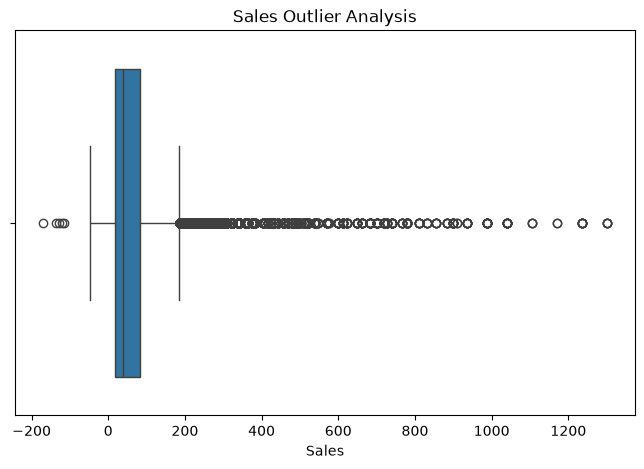

In [58]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Sales"])

plt.title("Sales Outlier Analysis")
plt.show()

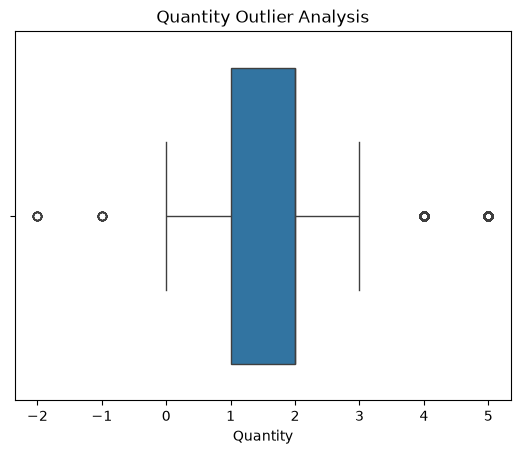

In [59]:
sns.boxplot(x=df["Quantity"])

plt.title("Quantity Outlier Analysis")
plt.show()

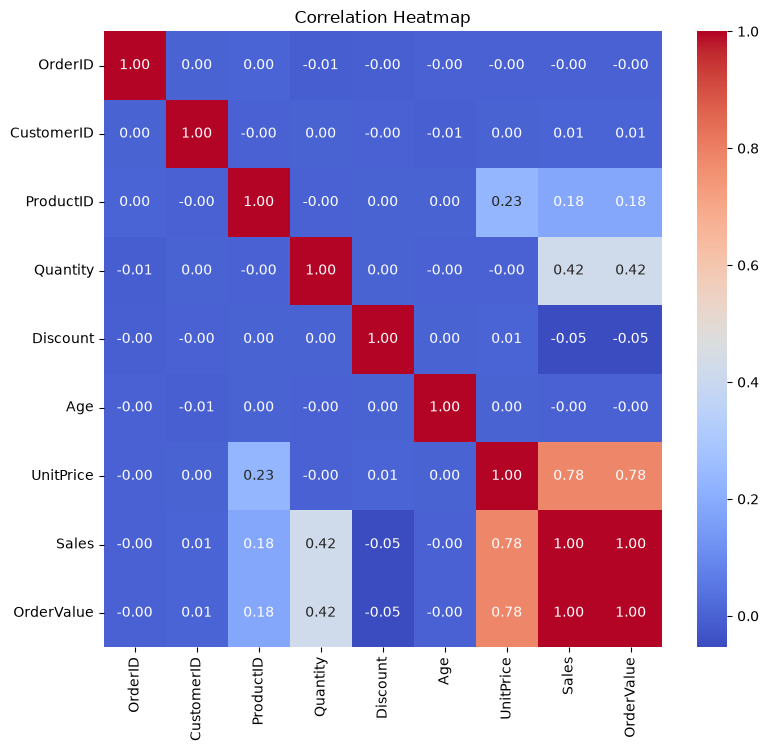

In [69]:
plt.figure(figsize=(9,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [66]:
numeric_df = df.select_dtypes(include="number")

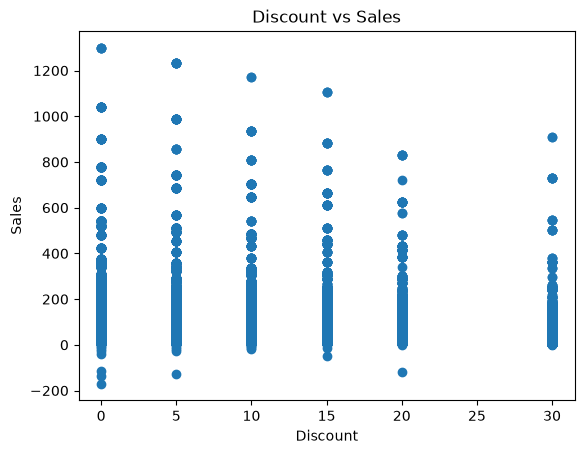

In [63]:
plt.scatter(df["Discount"], df["Sales"])

plt.title("Discount vs Sales")
plt.xlabel("Discount")
plt.ylabel("Sales")
plt.show()

In [64]:
df.groupby("ProductName")["Sales"].sum().sort_values(ascending=False).head(10)

ProductName
Headphones             333411.0
Office Chair           329292.0
Tablet                 292344.0
Smart Watch            259590.0
Microphone             230139.0
Mechanical Keyboard    229676.0
Bluetooth Speaker      213311.0
Gaming Controller      198037.0
Power Bank             180004.0
Fitness Band           169860.0
Name: Sales, dtype: float64